# Planar Adam engineering

Joint position/stiffness Adam with no-crossing constraints; frozen ML optimization followed by final-only LAMMPS verification. All 40 declared cases remain visible, including two user-cancelled optimizations. The GIFs show actual verification trajectories.


In [ ]:
# Choose "light" or "dark", then rerun the plotting cells.
PLOT_THEME = "light"
from lss.plotting import apply_editorial_style
apply_editorial_style(PLOT_THEME)


**Progress snapshot:** unfinished verifications are marked pending. GIFs appear as their jobs finish; rerun these cells to refresh.

,source,status,Networks
0,depablo_mixed_temp,cancelled_by_user,2
1,depablo_mixed_temp,completed,1
2,depablo_mixed_temp,trajectory_crossing,5
3,depablo_mixed_temp,verification_pending,22
4,reid,trajectory_crossing,10


Blue: verified without detected trajectory contacts. Red: geometry-invalid verification. Mixed-T values average all three paired velocity seeds.

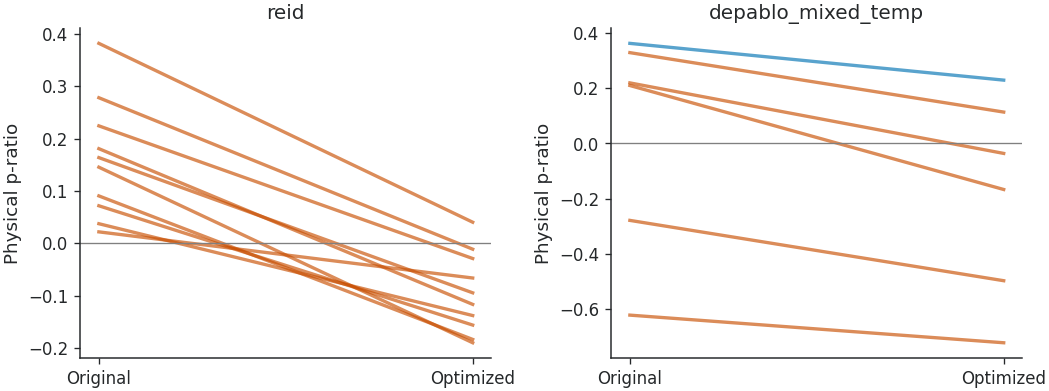

In [2]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from lss.plotting import apply_editorial_style, PAPER_COLORS
apply_editorial_style(PLOT_THEME)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/lss').is_dir())
RESULTS = ROOT / 'notebooks/results/planar_engineering/study_v1'
data = pd.read_csv(RESULTS / 'summary.csv')
display(Markdown('**Progress snapshot:** unfinished verifications are marked pending. GIFs appear as their jobs finish; rerun these cells to refresh.'))
display(data.groupby(['source', 'status']).size().rename('Networks').reset_index())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, source in zip(axes, ['reid', 'depablo_mixed_temp']):
    rows = data[data.source.eq(source)].dropna(subset=['original_p_ratio', 'optimized_p_ratio'])
    for row in rows.itertuples():
        good = row.status == 'completed'
        ax.plot([0, 1], [row.original_p_ratio, row.optimized_p_ratio],
                color=PAPER_COLORS['blue'] if good else PAPER_COLORS['red'], alpha=.65)
    ax.axhline(0, color='gray', lw=.8)
    ax.set(xticks=[0, 1], xticklabels=['Original', 'Optimized'], ylabel='Physical p-ratio', title=source)
fig.tight_layout()
display(Markdown('Blue: verified without detected trajectory contacts. Red: geometry-invalid verification. Mixed-T values average all three paired velocity seeds.'))


In [ ]:
# Two fixed illustrations per dataset; full-cohort statistics stay above.
from urllib.parse import quote
examples = [('reid', 93), ('reid', 84),
            ('depablo_mixed_temp', 47), ('depablo_mixed_temp', 68)]
assets = ROOT / 'notebooks/engineering/Planar Adam engineering'
display(Markdown('[All comparison GIFs](Planar%20Adam%20engineering/)'))
for source, index in examples:
    row = data[data.source.eq(source) & data['index'].eq(index)].iloc[0]
    display(Markdown(f'**{source} {index} — {row.status}**'))
    path = assets / f'{source}_{index}.gif'
    if path.is_file():
        # Reference the separate file; do not store GIF bytes in notebook outputs.
        url = quote(f'Planar Adam engineering/{path.name}')
        display(Image(url=url, embed=False, width=720))
    else:
        display(Markdown('Animation not available yet.'))
